#  임베딩(Embedding) 실습 노트북

「자연어 / 이미지 / 음성 임베딩」 강의자료의 핵심 개념을 **코드로 직접 확인**해보는 실습입니다.


## 목차
- **Part 0.** 환경 준비
- **Part 1.** 텍스트 임베딩 — One-hot의 한계 → 코사인 유사도 → Word2Vec 직접 학습 → King-Man+Woman=Queen → 임베딩 공간 시각화 → OOV 문제
- **Part 2.** 이미지 임베딩 — 이미지 = 숫자 벡터 → PCA로 임베딩 공간 시각화 → 유사 이미지 검색 → 엣지 필터 체험
- **Part 3.** 오디오 임베딩 — 유성음/무성음 신호 만들기 → Spectrogram → Mel-Spectrogram → MFCC → 발음 vs 음높이 분리


---
## Part 0. 환경 준비

아래 셀에서 필요한 패키지를 임포트합니다. 만약 `ModuleNotFoundError`가 뜨면
주석 처리된 `pip install` 명령어를 실행 후 다시 시도하세요.


In [9]:
# 처음 실행 시 아래 줄의 주석을 풀고 한 번 실행하세요 (이미 설치되어 있다면 건너뛰어도 됩니다)
!pip install gensim scikit-learn matplotlib librosa numpy

import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['axes.unicode_minus'] = False  # 마이너스 기호 깨짐 방지

print("환경 준비 완료 ")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 68.6 MB/s eta 0:00:00
환경 준비 완료 


---
# Part 1. 텍스트 임베딩

강의자료 슬라이드 12 "단순 숫자 부여의 한계"에서 다뤘던 것처럼,
컴퓨터에게 단어를 이해시키는 가장 단순한 방법은 **원-핫 인코딩(One-Hot Encoding)** 입니다.
하지만 이 방식은 "의미"를 전혀 담지 못합니다. 직접 확인해봅시다.


### 1.1 원-핫 인코딩의 한계 체험하기

'고양이', '강아지', '자동차' 세 단어를 원-핫 벡터로 만들고,
'고양이'-'강아지' 사이의 유사도와 '고양이'-'자동차' 사이의 유사도를 비교해봅니다.

직관적으로는 '고양이'와 '강아지'가 더 비슷해야 하는데, 결과가 어떻게 나올까요?


In [10]:
words = ['고양이', '강아지', '자동차']
vocab_size = len(words)

# 원-핫 벡터 생성: 단어마다 한 자리만 1, 나머지는 0
one_hot = {}
for i, w in enumerate(words):
    vec = np.zeros(vocab_size)
    vec[i] = 1
    one_hot[w] = vec

for w, v in one_hot.items():
    print(f"{w}: {v}")


고양이: [1. 0. 0.]
강아지: [0. 1. 0.]
자동차: [0. 0. 1.]


In [11]:
def cosine_similarity(a, b):
    # 코사인 유사도를 직접 구현 (강의자료 슬라이드 17의 공식 그대로)
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-8)

sim_cat_dog = cosine_similarity(one_hot['고양이'], one_hot['강아지'])
sim_cat_car = cosine_similarity(one_hot['고양이'], one_hot['자동차'])

print(f"원-핫 벡터 기준 '고양이' vs '강아지' 유사도: {sim_cat_dog:.3f}")
print(f"원-핫 벡터 기준 '고양이' vs '자동차' 유사도: {sim_cat_car:.3f}")
print("\n 두 값이 똑같이 0입니다. 원-핫 벡터는 '의미의 가까움'을 전혀 반영하지 못합니다!")

원-핫 벡터 기준 '고양이' vs '강아지' 유사도: 0.000
원-핫 벡터 기준 '고양이' vs '자동차' 유사도: 0.000

 두 값이 똑같이 0입니다. 원-핫 벡터는 '의미의 가까움'을 전혀 반영하지 못합니다!


### 1.2 의미를 담은 벡터라면 어떻게 다를까?

이번엔 '동물다움', '탈것다움'이라는 2개의 (가상의) 의미 축으로 직접 벡터를 만들어보겠습니다.
이게 바로 임베딩의 핵심 아이디어입니다 — **의미가 비슷하면 벡터도 가까워야 한다.**


Semantic similarity: 'Cat' vs. 'Dog': 0.998
Semantic similarity: 'Cat' vs. 'Car': 0.163

Now, 'Cat' and 'Dog' have a much higher similarity.
Models such as Word2Vec and GloVe automatically learn these semantic dimensions from data.


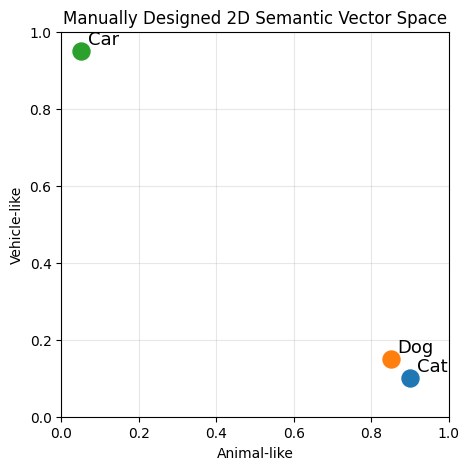

In [12]:
# Manually design a 2D semantic space: [animal-like, vehicle-like]
manual_embedding = {
    'Cat': np.array([0.9, 0.1]),
    'Dog': np.array([0.85, 0.15]),
    'Car': np.array([0.05, 0.95]),
}

sim_cat_dog = cosine_similarity(
    manual_embedding['Cat'],
    manual_embedding['Dog']
)

sim_cat_car = cosine_similarity(
    manual_embedding['Cat'],
    manual_embedding['Car']
)

print(f"Semantic similarity: 'Cat' vs. 'Dog': {sim_cat_dog:.3f}")
print(f"Semantic similarity: 'Cat' vs. 'Car': {sim_cat_car:.3f}")

print("\nNow, 'Cat' and 'Dog' have a much higher similarity.")
print(
    "Models such as Word2Vec and GloVe automatically learn "
    "these semantic dimensions from data."
)

# Visualization
fig, ax = plt.subplots(figsize=(5, 5))

for word, vector in manual_embedding.items():
    ax.scatter(*vector, s=150)
    ax.annotate(
        word,
        vector,
        fontsize=13,
        xytext=(5, 5),
        textcoords='offset points'
    )

ax.set_xlabel('Animal-like')
ax.set_ylabel('Vehicle-like')
ax.set_title('Manually Designed 2D Semantic Vector Space')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

plt.grid(alpha=0.3)
plt.show()

### 1.3 나만의 말뭉치로 Word2Vec 직접 학습하기 (CBOW vs Skip-gram)

이제 진짜 Word2Vec을 학습시켜 봅니다. 슬라이드 20~24에서 다룬 CBOW와 Skip-gram을
**둘 다 학습**시켜서 차이를 비교해봅니다.

문장이 적으면 학습이 잘 안 되기 때문에, 일부러 패턴이 뚜렷한 작은 말뭉치를
여러 번 반복해서 사용합니다.


In [13]:
from gensim.models import Word2Vec

# 성별 x 신분(왕족/평민) 패턴이 뚜렷하게 반복되는 장난감 말뭉치
base_sentences = [
    "king rules the kingdom with power and wears a crown".split(),
    "queen rules the kingdom with grace and wears a crown".split(),
    "prince will become king and rules the kingdom".split(),
    "princess will become queen and rules the kingdom".split(),
    "man walked into the room and sat down".split(),
    "woman walked into the room and sat down".split(),
    "father works hard for his man family every day".split(),
    "mother works hard for her woman family every day".split(),
]
corpus = base_sentences * 200  # 반복해서 패턴을 충분히 학습시킴

# CBOW: 주변 단어로 중심 단어 예측 (sg=0)
model_cbow = Word2Vec(corpus, vector_size=50, window=4, min_count=1, sg=0, epochs=30, seed=42)

# Skip-gram: 중심 단어로 주변 단어 예측 (sg=1)
model_sg = Word2Vec(corpus, vector_size=50, window=4, min_count=1, sg=1, epochs=30, seed=42)

print("=== CBOW로 학습된 'king'과 가장 유사한 단어 ===")
for w, s in model_cbow.wv.most_similar('king', topn=5):
    print(f"  {w:10s}  {s:.3f}")

print("\n=== Skip-gram으로 학습된 'king'과 가장 유사한 단어 ===")
for w, s in model_sg.wv.most_similar('king', topn=5):
    print(f"  {w:10s}  {s:.3f}")


=== CBOW로 학습된 'king'과 가장 유사한 단어 ===
  kingdom     0.791
  queen       0.783
  rules       0.765
  become      0.635
  will        0.624

=== Skip-gram으로 학습된 'king'과 가장 유사한 단어 ===
  kingdom     0.701
  rules       0.655
  queen       0.637
  crown       0.625
  a           0.602


> 데이터가 작아서 결과가 완벽하지 않을 수 있어요. 실제로는 수십억 단어 규모의 말뭉치를 씁니다.
> 슬라이드 24에서 배운 것처럼 **CBOW는 빠르고, Skip-gram은 희귀 단어에 강하다**는 특징을 기억해두세요.


### 1.4 벡터 연산: King - Man + Woman = Queen (사전학습 GloVe 사용)

우리가 만든 장난감 말뭉치는 너무 작아서 완벽한 유추가 어렵습니다.
이번엔 **수십억 단어로 미리 학습된 GloVe** 임베딩을 다운로드해서 슬라이드 11, 15의
그 유명한 벡터 연산을 직접 확인해봅니다. (처음 실행 시 약 66MB 다운로드, 1분 내외 소요)


In [14]:
import gensim.downloader as api

print("GloVe(50차원) 임베딩을 불러오는 중입니다... (최초 1회만 다운로드)")
glove = api.load('glove-wiki-gigaword-50')
print(f"불러오기 완료! 어휘 수: {len(glove):,}개, 벡터 차원: {glove.vector_size}")


GloVe(50차원) 임베딩을 불러오는 중입니다... (최초 1회만 다운로드)
[==================================================] 100.0% 66.0/66.0MB downloaded
불러오기 완료! 어휘 수: 400,000개, 벡터 차원: 50


In [15]:
# King - Man + Woman = ?
result = glove.most_similar(positive=['king', 'woman'], negative=['man'], topn=5)
print("king - man + woman = ?")
for w, s in result:
    print(f"  {w:10s}  {s:.3f}")

print()
# 다른 유추도 해보기: Seoul - Korea + Japan = ?
result2 = glove.most_similar(positive=['seoul', 'japan'], negative=['korea'], topn=5)
print("seoul - korea + japan = ?")
for w, s in result2:
    print(f"  {w:10s}  {s:.3f}")


king - man + woman = ?
  queen       0.852
  throne      0.766
  prince      0.759
  daughter    0.747
  elizabeth   0.746

seoul - korea + japan = ?
  tokyo       0.938
  osaka       0.833
  shanghai    0.811
  beijing     0.785
  taipei      0.772


**직접 해보기** 아래 셀의 단어들을 바꿔서 나만의 유추 문제를 만들어보세요.
(예: `paris - france + italy`, `bigger - big + small` 등)


In [16]:
# 여기 단어들을 자유롭게 바꿔보세요!
positive_words = ['paris', 'italy']
negative_words = ['france']

result3 = glove.most_similar(positive=positive_words, negative=negative_words, topn=5)
print(f"{' + '.join(positive_words)} - {' + '.join(negative_words)} = ?")
for w, s in result3:
    print(f"  {w:10s}  {s:.3f}")

paris + italy - france = ?
  rome        0.847
  milan       0.777
  turin       0.767
  venice      0.759
  madrid      0.757


### 1.5 임베딩 공간 시각화하기 (PCA로 50차원 → 2차원 축소)

슬라이드 9, 11에서 본 "벡터 공간에서 의미가 비슷한 단어는 가깝게 모인다"는 개념을
실제 GloVe 벡터로 확인해봅니다. 50차원은 눈으로 볼 수 없으니, PCA로 2차원으로 압축합니다.


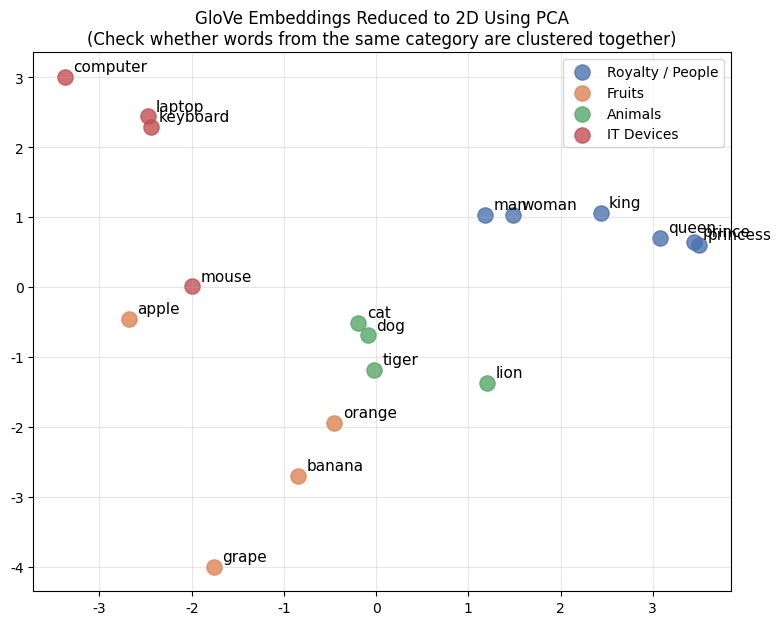

In [19]:
from sklearn.decomposition import PCA

words_to_plot = [
    'king', 'queen', 'prince', 'princess', 'man', 'woman',
    'apple', 'banana', 'orange', 'grape',
    'dog', 'cat', 'lion', 'tiger',
    'computer', 'laptop', 'keyboard', 'mouse',
]
vectors = np.array([glove[w] for w in words_to_plot])

pca = PCA(n_components=2)
vectors_2d = pca.fit_transform(vectors)

# Use different colors for each category
groups = {
    'Royalty / People': words_to_plot[0:6],
    'Fruits': words_to_plot[6:10],
    'Animals': words_to_plot[10:14],
    'IT Devices': words_to_plot[14:18],
}
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

fig, ax = plt.subplots(figsize=(9, 7))

for (label, group_words), color in zip(groups.items(), colors):
    idxs = [words_to_plot.index(w) for w in group_words]

    ax.scatter(
        vectors_2d[idxs, 0],
        vectors_2d[idxs, 1],
        c=color,
        s=120,
        label=label,
        alpha=0.8
    )

    for i in idxs:
        ax.annotate(
            words_to_plot[i],
            vectors_2d[i],
            fontsize=11,
            xytext=(6, 4),
            textcoords='offset points'
        )

ax.set_title(
    'GloVe Embeddings Reduced to 2D Using PCA\n'
    '(Check whether words from the same category are clustered together)'
)

ax.legend()
plt.grid(alpha=0.3)
plt.show()

### 1.6 OOV(미등록어) 문제 체험: Word2Vec vs FastText

슬라이드 42~44에서 다룬 것처럼, Word2Vec은 훈련 데이터에 없던 단어(오탈자, 신조어 등)를
만나면 아예 벡터를 만들지 못합니다. 반면 FastText는 **n-gram(문자 조각)** 덕분에
처음 보는 단어도 벡터를 합성해낼 수 있습니다. 1.3에서 학습한 모델로 직접 비교해봅시다.


In [20]:
from gensim.models import FastText

# 같은 말뭉치로 FastText도 학습
model_ft = FastText(corpus, vector_size=50, window=4, min_count=1, sg=1, epochs=30, seed=42)

oov_word = 'kingdoms'  # 말뭉치에 없던 단어 (king의 복수형)

print(f"'{oov_word}'는 학습 말뭉치에 등장한 적이 없습니다.\n")

# Word2Vec은 실패한다
try:
    model_sg.wv[oov_word]
    print("Word2Vec: 성공 (예상치 못한 결과)")
except KeyError as e:
    print(f" Word2Vec 결과: KeyError -> {e}")

# FastText는 성공한다
try:
    vec = model_ft.wv[oov_word]
    print(f" FastText 결과: 벡터 생성 성공! (차원: {vec.shape})")
    similar = model_ft.wv.most_similar(oov_word, topn=3)
    print(f"   '{oov_word}'와 가장 유사한 단어들: {similar}")
except KeyError as e:
    print(f"FastText 결과: 실패 -> {e}")


'kingdoms'는 학습 말뭉치에 등장한 적이 없습니다.

 Word2Vec 결과: KeyError -> "Key 'kingdoms' not present"
 FastText 결과: 벡터 생성 성공! (차원: (50,))
   'kingdoms'와 가장 유사한 단어들: [('kingdom', 0.9989984035491943), ('king', 0.9548871517181396), ('rules', 0.873594343662262)]


---
# Part 2. 이미지 임베딩

슬라이드 64~68에서 배운 "이미지 임베딩: 픽셀에서 벡터로"를 직접 확인해봅니다.
무거운 딥러닝 모델을 다운로드하지 않고도, **손글씨 숫자 이미지**를 이용해
"이미지 = 숫자 벡터"라는 핵심 개념과 임베딩 공간을 체험할 수 있습니다.


### 2.1 이미지는 사실 숫자 벡터일 뿐

8x8 픽셀짜리 손글씨 숫자(0~9) 이미지 데이터셋을 불러옵니다.
이미지 한 장 = 64개의 픽셀 값 = **64차원 벡터**입니다.


이미지 개수: 1797장
이미지 한 장의 크기: 8x8 = 64차원 벡터


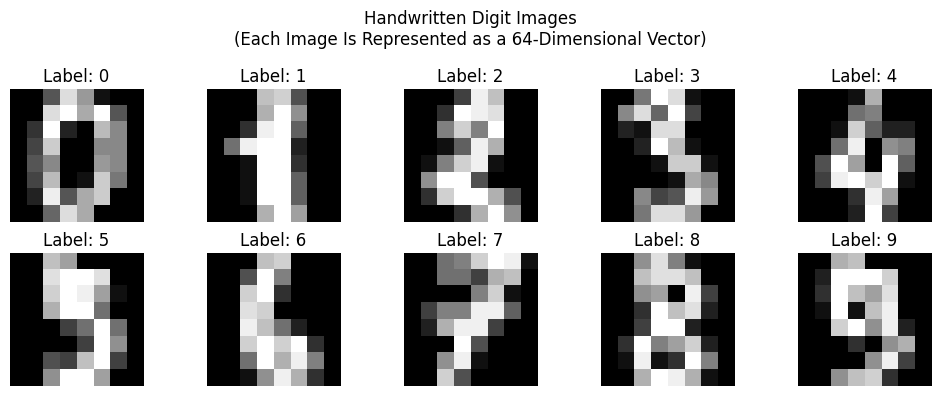

In [21]:
from sklearn.datasets import load_digits

digits = load_digits()
print(f"이미지 개수: {digits.images.shape[0]}장")
print(f"이미지 한 장의 크기: {digits.images.shape[1]}x{digits.images.shape[2]} = {digits.data.shape[1]}차원 벡터")

# Visualize a few sample images
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap='gray')
    ax.set_title(f"Label: {digits.target[i]}")
    ax.axis('off')

plt.suptitle("Handwritten Digit Images\n(Each Image Is Represented as a 64-Dimensional Vector)")
plt.tight_layout()
plt.show()


### 2.2 PCA로 이미지 임베딩 공간 시각화하기

64차원 벡터를 2차원으로 압축해서, 슬라이드 9의 "임베딩 벡터 공간" 그림처럼
**같은 숫자끼리 뭉치는지** 확인해봅니다. (이 자체가 이미지 임베딩의 핵심입니다!)


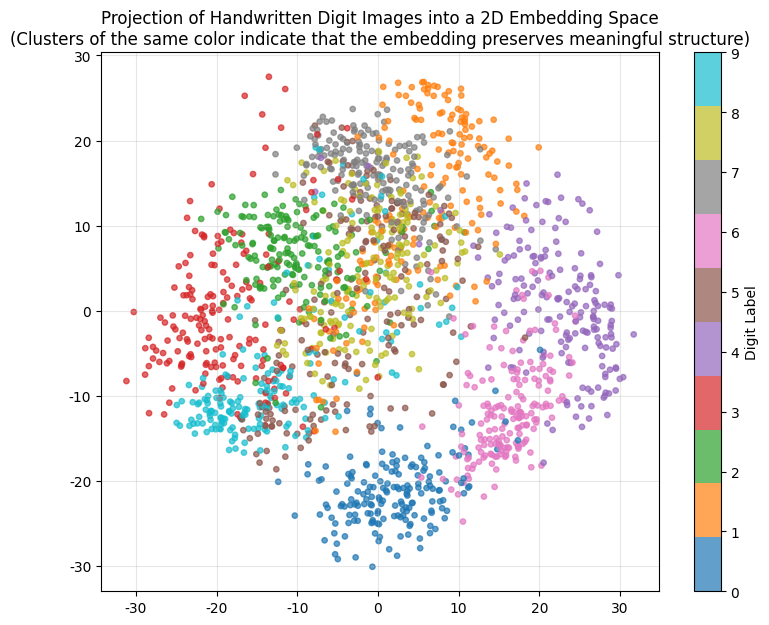

In [23]:
pca_img = PCA(n_components=2)
digits_2d = pca_img.fit_transform(digits.data)

fig, ax = plt.subplots(figsize=(9, 7))

scatter = ax.scatter(
    digits_2d[:, 0],
    digits_2d[:, 1],
    c=digits.target,
    cmap='tab10',
    s=15,
    alpha=0.7
)

plt.colorbar(scatter, label='Digit Label')

ax.set_title(
    'Projection of Handwritten Digit Images into a 2D Embedding Space\n'
    '(Clusters of the same color indicate that the embedding preserves meaningful structure)'
)

plt.grid(alpha=0.3)
plt.show()

### 2.3 코사인 유사도로 비슷한 이미지 찾기 (이미지 검색)

슬라이드 6의 "검색과 추천 가능" 개념을 이미지에 적용해봅니다.
아무 이미지 하나를 골라서, 벡터 공간에서 **가장 가까운 이미지 5장**을 찾아봅니다.


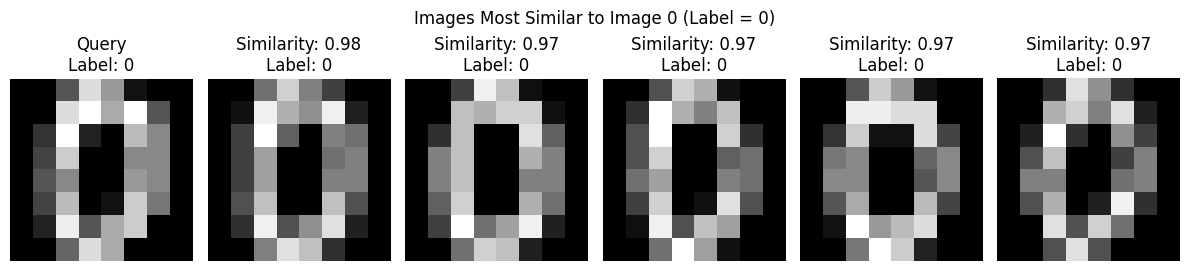

In [24]:
from sklearn.metrics.pairwise import cosine_similarity as sk_cosine_similarity

query_idx = 0  # Change this value to select a different query image
query_vec = digits.data[query_idx].reshape(1, -1)

sims = sk_cosine_similarity(query_vec, digits.data)[0]
top5_idx = np.argsort(sims)[::-1][:6]  # Top 6, including the query image itself

fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for ax, idx in zip(axes, top5_idx):
    ax.imshow(digits.images[idx], cmap='gray')

    tag = "Query" if idx == query_idx else f"Similarity: {sims[idx]:.2f}"

    ax.set_title(
        f"{tag}\nLabel: {digits.target[idx]}"
    )
    ax.axis('off')

plt.suptitle(
    f"Images Most Similar to Image {query_idx} "
    f"(Label = {digits.target[query_idx]})"
)

plt.tight_layout()
plt.show()

### 2.4 (보너스) 저차원 특징 체험: 엣지(Edge) 필터

슬라이드 61 "1단계: 저차원 특징"에서 CNN의 첫 번째 층이 하는 일이 바로
엣지(테두리) 감지입니다. 소벨(Sobel) 필터로 직접 체험해봅니다.


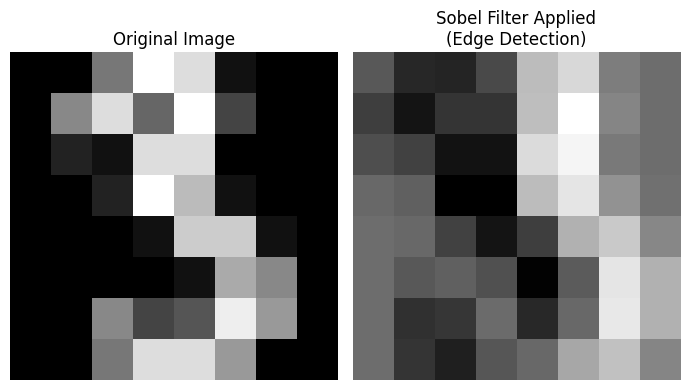

The first convolutional layer of a CNN detects low-level features such as lines and edges.


In [25]:
from scipy.signal import convolve2d

sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])  # Vertical edge detection filter

sample = digits.images[3]  # Digit '3' image
edge_map = convolve2d(sample, sobel_x, mode='same')

fig, axes = plt.subplots(1, 2, figsize=(7, 4))

axes[0].imshow(sample, cmap='gray')
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(edge_map, cmap='gray')
axes[1].set_title('Sobel Filter Applied\n(Edge Detection)')
axes[1].axis('off')

plt.tight_layout()
plt.show()

print(
    "The first convolutional layer of a CNN detects "
    "low-level features such as lines and edges."
)

---
# Part 3. 오디오 임베딩 (MFCC)

슬라이드 76~88에서 다룬 "Spectrum → Mel-Spectrogram → MFCC" 파이프라인을
직접 만든 합성 음성 신호로 체험해봅니다. 실제 목소리 파일 없이도 개념을 확인할 수 있습니다.


In [26]:
import librosa
import librosa.display

sr = 16000  # 샘플링 레이트
duration = 1.0
t = np.linspace(0, duration, int(sr * duration))


### 3.1 유성음 vs 무성음 신호 직접 만들기

슬라이드 80 "초기 신호를 결정하는 성대 진동의 유무"를 코드로 재현합니다.
- **유성음**: 기본 주파수(f0) + 배음(harmonics)이 섞인 규칙적인 파형 (모음처럼)
- **무성음**: 규칙성이 없는 백색소음 (마찰음 'ㅅ' 같은 소리처럼)


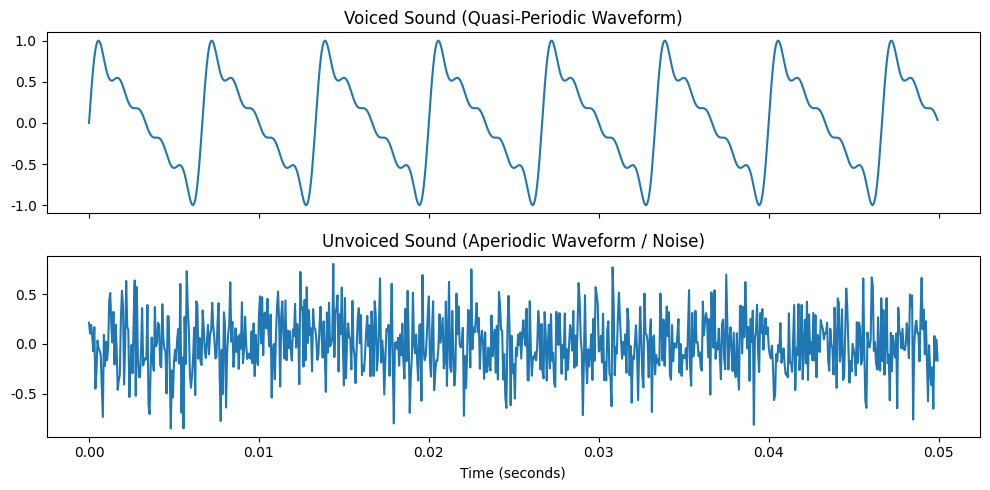

In [27]:
f0 = 150  # Fundamental frequency (vocal fold vibration rate, Hz)

# Voiced sound: fundamental frequency + five harmonics
voiced = sum(np.sin(2 * np.pi * f0 * h * t) / h for h in range(1, 6))
voiced = voiced / np.max(np.abs(voiced))

# Unvoiced sound: white noise
unvoiced = np.random.normal(0, 0.3, len(t))

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

axes[0].plot(t[:800], voiced[:800])
axes[0].set_title('Voiced Sound (Quasi-Periodic Waveform)')

axes[1].plot(t[:800], unvoiced[:800])
axes[1].set_title('Unvoiced Sound (Aperiodic Waveform / Noise)')
axes[1].set_xlabel('Time (seconds)')

plt.tight_layout()
plt.show()

# Combine the two signals: 0.5 seconds voiced + 0.5 seconds unvoiced
signal = np.concatenate([voiced[:sr // 2], unvoiced[:sr // 2]])

### 3.2 STFT & Spectrogram

시간에 따라 어떤 주파수 성분이 존재하는지 보여주는 스펙트로그램을 그려봅니다.


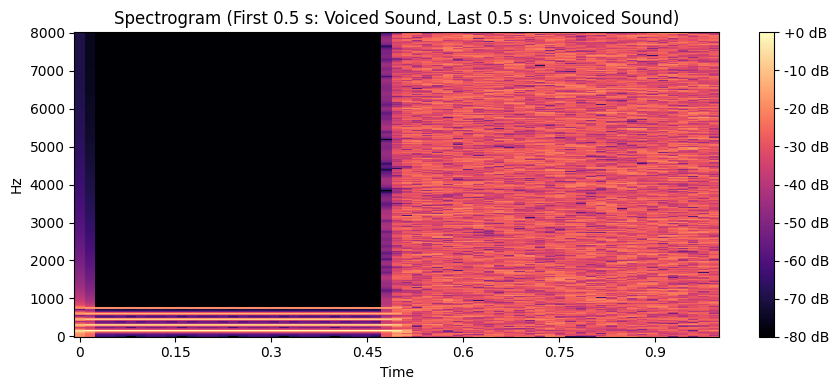

 유성음 구간에는 f0(150Hz)와 그 배음들이 뚜렷한 가로줄로 보이고,
  무성음 구간은 모든 주파수에 에너지가 퍼져있는 것을 확인할 수 있습니다.


In [28]:
D = librosa.stft(signal, n_fft=1024, hop_length=256)
S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

fig, ax = plt.subplots(figsize=(9, 4))

img = librosa.display.specshow(
    S_db,
    sr=sr,
    hop_length=256,
    x_axis='time',
    y_axis='hz',
    ax=ax
)

ax.set_title(
    'Spectrogram '
    '(First 0.5 s: Voiced Sound, Last 0.5 s: Unvoiced Sound)'
)

fig.colorbar(img, ax=ax, format='%+2.0f dB')
plt.tight_layout()
plt.show()

print(" 유성음 구간에는 f0(150Hz)와 그 배음들이 뚜렷한 가로줄로 보이고,")
print("  무성음 구간은 모든 주파수에 에너지가 퍼져있는 것을 확인할 수 있습니다.")

### 3.3 Mel-Spectrogram

사람 귀는 저주파에 민감하고 고주파에 둔감합니다. Mel-Scale은 이 청각 특성을
반영해 주파수 축을 왜곡시킨 것입니다. 일반 스펙트로그램과 비교해봅니다.


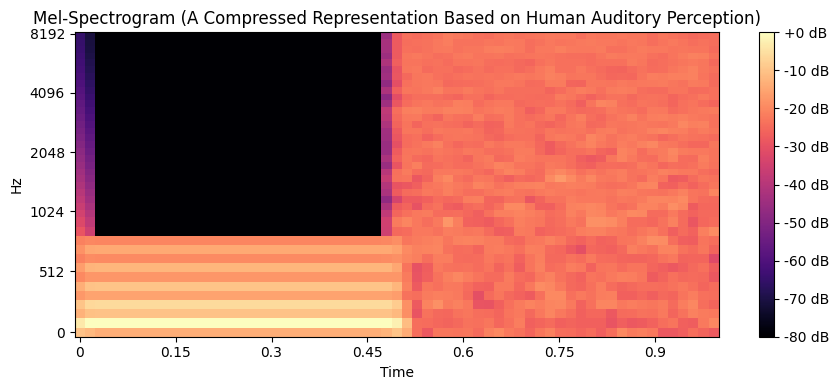

일반 Spectrogram 크기: (513, 63)  (주파수 bin이 513개)
Mel-Spectrogram 크기: (40, 63)  (mel bin이 40개로 압축됨)


In [29]:
mel_spec = librosa.feature.melspectrogram(
    y=signal,
    sr=sr,
    n_mels=40,
    n_fft=1024,
    hop_length=256
)
mel_db = librosa.power_to_db(mel_spec, ref=np.max)

fig, ax = plt.subplots(figsize=(9, 4))

img = librosa.display.specshow(
    mel_db,
    sr=sr,
    hop_length=256,
    x_axis='time',
    y_axis='mel',
    ax=ax
)

ax.set_title(
    'Mel-Spectrogram '
    '(A Compressed Representation Based on Human Auditory Perception)'
)

fig.colorbar(img, ax=ax, format='%+2.0f dB')
plt.tight_layout()
plt.show()

print(f"일반 Spectrogram 크기: {S_db.shape}  (주파수 bin이 {S_db.shape[0]}개)")
print(f"Mel-Spectrogram 크기: {mel_db.shape}  (mel bin이 {mel_db.shape[0]}개로 압축됨)")

### 3.4 MFCC 추출하기

Mel-Spectrogram에 로그를 취하고 역푸리에변환(IFFT)까지 적용하면,
발음(성도 모양)과 음색/음높이(성대 진동) 정보가 분리된 **MFCC**를 얻습니다.
이것이 음성 인식에서 가장 널리 쓰이는 최종 특징 벡터입니다.


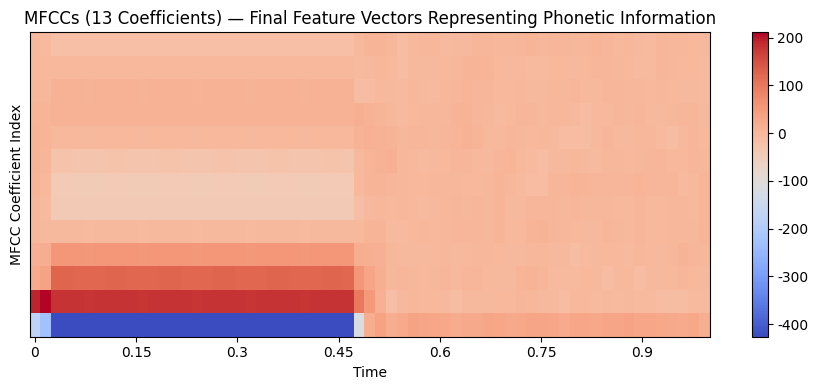

MFCC 벡터 shape: (13, 63)  → (13개 계수) x (시간 프레임 수)
각 시간 프레임마다 13차원 벡터 하나가 그 순간의 '소리 특징'을 압축해서 담고 있습니다.


In [30]:
mfcc = librosa.feature.mfcc(
    y=signal,
    sr=sr,
    n_mfcc=13,
    n_fft=1024,
    hop_length=256
)

fig, ax = plt.subplots(figsize=(9, 4))

img = librosa.display.specshow(
    mfcc,
    sr=sr,
    hop_length=256,
    x_axis='time',
    ax=ax
)

ax.set_ylabel('MFCC Coefficient Index')
ax.set_title(
    'MFCCs (13 Coefficients) — Final Feature Vectors '
    'Representing Phonetic Information'
)

fig.colorbar(img, ax=ax)
plt.tight_layout()
plt.show()

print(f"MFCC 벡터 shape: {mfcc.shape}  → (13개 계수) x (시간 프레임 수)")
print("각 시간 프레임마다 13차원 벡터 하나가 그 순간의 '소리 특징'을 압축해서 담고 있습니다.")

### 3.5 MFCC는 정말 음높이(pitch)와 무관하게 발음만 담을까?
.
**같은 모음(배음 구조 비율)** 을 **다른 음높이(f0)** 로 만들어서 MFCC를 비교합니다.
정말로 음높이가 달라도 MFCC가 비슷하게 나올까요?


In [31]:
def make_vowel(f0, n_harmonics=5, sr=16000, duration=0.5):
    # 기본주파수(f0)와 배음 개수(n_harmonics)로 합성 모음 신호를 만든다
    tt = np.linspace(0, duration, int(sr*duration))
    sig = sum(np.sin(2*np.pi*f0*h*tt) / h for h in range(1, n_harmonics+1))
    return sig / np.max(np.abs(sig))

def get_mfcc_mean(sig, sr=16000):
    # MFCC를 뽑은 뒤 시간 축으로 평균내서 하나의 벡터로 요약
    m = librosa.feature.mfcc(y=sig, sr=sr, n_mfcc=13, n_fft=1024, hop_length=256)
    return m.mean(axis=1)

# 같은 '모음'을, 낮은 목소리(f0=100Hz)와 높은 목소리(f0=220Hz)로 만들어봄
vowel_low_pitch  = make_vowel(f0=100)
vowel_high_pitch = make_vowel(f0=220)
# 완전히 다른 종류의 소리 (배음 구조가 다른 모음이라고 가정, f0는 vowel_low_pitch와 동일)
different_sound  = make_vowel(f0=100, n_harmonics=2)  # 배음 개수를 다르게 -> 다른 '음색/발음'

mfcc_low  = get_mfcc_mean(vowel_low_pitch)
mfcc_high = get_mfcc_mean(vowel_high_pitch)
mfcc_diff = get_mfcc_mean(different_sound)

sim_same_vowel_diff_pitch = cosine_similarity(mfcc_low, mfcc_high)
sim_diff_vowel_same_pitch = cosine_similarity(mfcc_low, mfcc_diff)

print(f"같은 모음 / 다른 음높이(100Hz vs 220Hz)  → MFCC 유사도: {sim_same_vowel_diff_pitch:.3f}")
print(f"다른 모음(배음구조) / 같은 음높이(100Hz)   → MFCC 유사도: {sim_diff_vowel_same_pitch:.3f}")
print()
print(" 음높이만 다른 경우가, 음색(발음)이 다른 경우보다 MFCC 유사도가 더 높게 나온다면")
print("   MFCC가 '누가 말했는지/얼마나 높은 소리인지'보다 '무슨 소리인지(발음)'를 더 잘 담고 있다는 뜻입니다.")


같은 모음 / 다른 음높이(100Hz vs 220Hz)  → MFCC 유사도: 0.910
다른 모음(배음구조) / 같은 음높이(100Hz)   → MFCC 유사도: 0.952

 음높이만 다른 경우가, 음색(발음)이 다른 경우보다 MFCC 유사도가 더 높게 나온다면
   MFCC가 '누가 말했는지/얼마나 높은 소리인지'보다 '무슨 소리인지(발음)'를 더 잘 담고 있다는 뜻입니다.
